# Crossing beams and shadow

Two tests of the ray closure in optically thin regions from the IDORT paper (Ma et al. 2025,
sec. 4.1.1 and 4.1.4) and Jiang (2021, ApJS 253, 49, sec. 4.2 and 4.3), with the production
keys (`decks/idort_beams.athinput`, `decks/idort_shadow*.athinput`):

- **crossing beams** in vacuum (`idort_beams`): two beams enter at $x_1 = -2$ at $\pm 45$ deg
  and wrap through the periodic $x_2$ boundary; exact: the straight beams. Also on 4
  MeshBlocks (`idort_beams_mb`, no plot: identical in tile mode).
- **shadow** (`idort_shadow`, ring of 12 rays; `idort_shadow_gl`, the general $8\times32$ set):
  two beams at $\pm15$ deg past an opaque ellipse; exact: the beams attenuated along straight rays.

Criteria: L1 within 5 % of the reference values (`ref/references.json`). Code units.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
ATHENAK = os.path.abspath(os.environ.get('ATHENAK', '../../athenak'))   # your athenak checkout
sys.path.insert(0, os.path.join(ATHENAK, 'tests/vet_clean/notebooks'))
import nbutil as nb                        # nb.suite, nb.verdict, nb.vett (readers), nb.rt (run_tests)

# the athena binary (a CPU build, default the one tests/vet_clean/run_tests.sh builds)
EXE = os.path.abspath(os.environ.get('ATHENA_EXE', os.path.join(ATHENAK, 'build_tests/src/athena')))
# where the runs go; a test whose run is already there is only loaded, not rerun
WORK = os.path.abspath(os.environ.get('M1_NB_WORKDIR', 'runs'))
THREADS = int(os.environ.get('M1_NB_THREADS', '4'))   # OpenMP threads per run
plt.rcParams.update({'figure.dpi': 80, 'savefig.dpi': 80, 'font.size': 10})
print('binary', os.path.relpath(EXE), '\nruns  ', os.path.relpath(WORK))

binary $ATHENA_EXE 
runs   runs


In [2]:
TESTS = ['idort_beams', 'idort_beams_mb', 'idort_shadow', 'idort_shadow_gl']
res = {t: nb.suite(t, EXE, WORK, THREADS) for t in TESTS}
vett, rt = nb.vett, nb.rt

running: python3 $ATHENAK/tests/vet_clean/run_tests.py --exe $ATHENA_EXE --only idort_beams --keep --workdir runs --threads 4 --record runs/idort_beams.json


clean VET test suite: 1 tests, full, 56 at a time x 4 threads, binary $ATHENA_EXE
PASS idort_beams          11 s  L1 0.777 lum_top 1.79
1 passed, 0 failed, 11 s

running: python3 $ATHENAK/tests/vet_clean/run_tests.py --exe $ATHENA_EXE --only idort_beams_mb --keep --workdir runs --threads 4 --record runs/idort_beams_mb.json


clean VET test suite: 1 tests, full, 56 at a time x 4 threads, binary $ATHENA_EXE
PASS idort_beams_mb       38 s  maxdiff_tile_x2 0 maxdiff_block_x1 2.05e-11
1 passed, 0 failed, 38 s

running: python3 $ATHENAK/tests/vet_clean/run_tests.py --exe $ATHENA_EXE --only idort_shadow --keep --workdir runs --threads 4 --record runs/idort_shadow.json


clean VET test suite: 1 tests, full, 56 at a time x 4 threads, binary $ATHENA_EXE
PASS idort_shadow          3 s  L1 0.0138
1 passed, 0 failed, 3 s

running: python3 $ATHENAK/tests/vet_clean/run_tests.py --exe $ATHENA_EXE --only idort_shadow_gl --keep --workdir runs --threads 4 --record runs/idort_shadow_gl.json


clean VET test suite: 1 tests, full, 56 at a time x 4 threads, binary $ATHENA_EXE
PASS idort_shadow_gl       5 s  L1 0.0126
1 passed, 0 failed, 5 s



## Crossing beams

Left: E of the run; middle: the exact straight beams (cell averages); right: cuts across the
beams at four heights $x_1$ (lines: code, dashed: exact). The beams stay straight and 1-2
cells wide and cross without interacting; a beam narrower than a cell carries about 1.8 times
the exact energy density at this resolution (`lum_top`), which dominates L1.

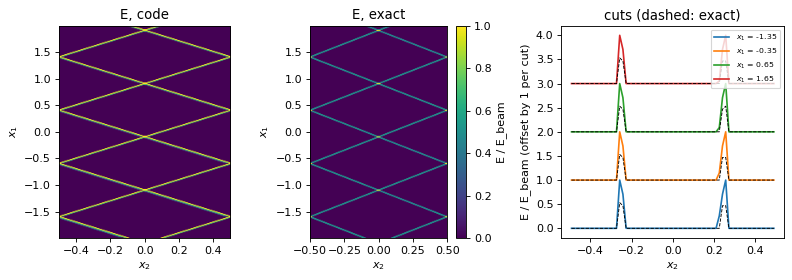

PASS idort_beams   criterion {"near": {"L1": [0.777, 0.05], "lum_top": [1.785, 0.05]}}
PASS idort_beams_mb   criterion {"equal": {"maxdiff_tile_x2": 0.0}, "max": {"maxdiff_block_x1": 1e-08}}


In [3]:
d = os.path.join(WORK, 'idort_beams', 'run')
E, Ex = vett.last_bin(d, 'vet')['vet_e'][0], rt.beams_exact(d)
x1, x2, _ = vett.cell_centres(d)
fig, axs = plt.subplots(1, 3, figsize=(10, 3.6), gridspec_kw={'width_ratios': [1, 1, 1.3]})
ext = [x2[0] - 0.5*(x2[1] - x2[0]), x2[-1] + 0.5*(x2[1] - x2[0]), x1[0], x1[-1]]
for a, f, t in ((axs[0], E, 'code'), (axs[1], Ex, 'exact')):
    im = a.imshow(f.T, origin='lower', extent=ext, aspect='auto', vmin=0, vmax=1, cmap='viridis')
    a.set(xlabel='$x_2$', ylabel='$x_1$', title='E, ' + t)
fig.colorbar(im, ax=axs[1], label='E / E_beam')
for k, r in enumerate((-1.35, -0.35, 0.65, 1.65)):
    i = int(np.argmin(np.abs(x1 - r)))
    axs[2].plot(x2, E[:, i] + k, '-', c='C%d' % k, label='$x_1$ = %.2f' % x1[i])
    axs[2].plot(x2, Ex[:, i] + k, 'k--', lw=0.8)
axs[2].set(xlabel='$x_2$', ylabel='E / E_beam (offset by 1 per cut)', title='cuts (dashed: exact)')
axs[2].legend(fontsize=7, loc='upper right')
plt.tight_layout(); plt.show()
for t in ('idort_beams', 'idort_beams_mb'):
    nb.verdict(t, res[t])

## Shadow

Left: E of the ring run, log scale. Right: cuts along $x_2$ behind the ellipse (at
$x_1 = 0.25$ and $0.4$) for both ray sets with the exact attenuated beams (the general set
snaps the beams to its nearest rays, 11.4 deg; its exact field uses that angle).

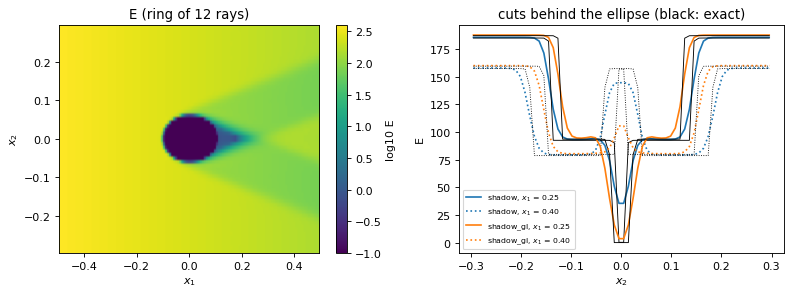

PASS idort_shadow   criterion {"near": {"L1": [0.0138, 0.05]}}
PASS idort_shadow_gl   criterion {"near": {"L1": [0.0126, 0.05]}}


In [4]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
for t, c in (('idort_shadow', 'C0'), ('idort_shadow_gl', 'C1')):
    d = os.path.join(WORK, t, 'run')
    E, Ex = vett.last_bin(d, 'vet')['vet_e'][0], rt.shadow_exact(d)
    x1, x2, _ = vett.cell_centres(d)
    if t == 'idort_shadow':
        im = axs[0].imshow(np.log10(np.maximum(E, 1e-3)), origin='lower', aspect='auto',
                           extent=[x1[0], x1[-1], x2[0], x2[-1]], vmin=-1, vmax=np.log10(400))
        fig.colorbar(im, ax=axs[0], label='log10 E')
        axs[0].set(xlabel='$x_1$', ylabel='$x_2$', title='E (ring of 12 rays)')
    for xc, ls in ((0.25, '-'), (0.4, ':')):
        i = int(np.argmin(np.abs(x1 - xc)))
        axs[1].plot(x2, E[:, i], ls, c=c, label='%s, $x_1$ = %.2f' % (t[6:], x1[i]))
        axs[1].plot(x2, Ex[:, i], ls, c='k', lw=0.8)
axs[1].set(xlabel='$x_2$', ylabel='E', title='cuts behind the ellipse (black: exact)')
axs[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
for t in ('idort_shadow', 'idort_shadow_gl'):
    nb.verdict(t, res[t])